# Plot Link Landuse Grids

Generate plots of land use shares for study area data.

<br><br>

## 0. Setup

### 0.1. Imports

In [1]:
import numpy as np
import pandas as pd

from splendor.config import CORRIDOR_RADIUS, SEED, STUDY_AREA
from splendor.io import load_network, load_raster
from splendor.landuse import get_link_corridors
from splendor.plotting import plot_link_landuse_grid
from splendor.paths import (
    basemap05_main_types_path, 
    ensure_parent,
    link_landuse_path,
    link_landuse_plot_path,
    network_path
)

### 0.2. Data

In [2]:
_, edges = load_network(network_path(STUDY_AREA))
edges = edges.sort_values("edge_id").reset_index(drop=True)
raster, transform, _ = load_raster(basemap05_main_types_path(STUDY_AREA))
shares = pd.read_csv(link_landuse_path(STUDY_AREA, CORRIDOR_RADIUS)).set_index("edge_id")
corridors = get_link_corridors(edges, CORRIDOR_RADIUS)

<br><br>

## 1. Random Links

### 1.1. Config

In [3]:
N_ROWS = 3
N_COLS = 4
N_LINKS = N_ROWS * N_COLS
MIN_SHARE = .01 # Exclude types with less share from bar panel

DETAIL = "random"
OUT = link_landuse_plot_path(STUDY_AREA, CORRIDOR_RADIUS, DETAIL)

### 1.2. Plot

Saved /Users/sanderengelthilo/dev/rp_bikenwsplendor/plots/pilot/link_landuse_random_r100.png


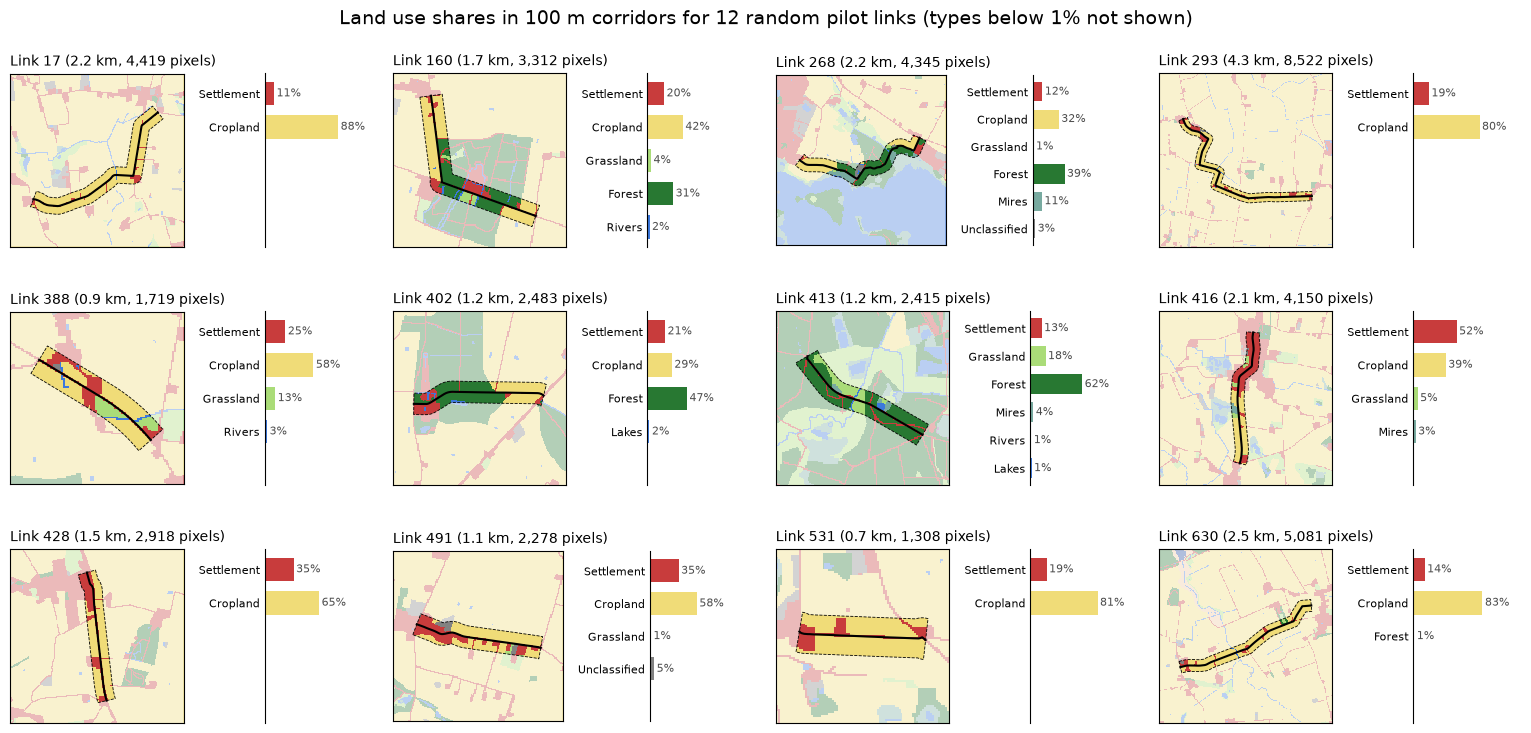

In [4]:
rng = np.random.default_rng(SEED)
edge_ids = np.sort(rng.choice(len(edges), size=N_LINKS, replace=False))

fig = plot_link_landuse_grid(
    edge_ids, edges, corridors, shares, raster, transform,
    n_cols=N_COLS, 
    title=f"Land use shares in {CORRIDOR_RADIUS} m corridors for {N_LINKS} {DETAIL} {STUDY_AREA} links "
    f"(types below {MIN_SHARE:.0%} not shown)", 
    min_share=MIN_SHARE
)
fig.savefig(ensure_parent(OUT), dpi=150)
print(f"Saved {OUT}")